[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch11-concepts_workbook.ipynb)

# Three models, one exam

Gopher has 280 billion parameters, GPT-3 175 billion and Chinchilla 70
billion. Gopher and Chinchilla were trained with the same compute, GPT-3 with
a little over half of it. Which of the three scores highest on MMLU, an exam
of 57 tasks? The lecture's numbers answer it: Kaplan's power law, the
twenty-to-one rule, exact match and the memory that training needs.

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MILLION, BILLION, TRILLION = 1_000_000, 10 ** 9, 10 ** 12
MMLU_TASKS = 57  # MMLU: 57 tasks, scored 5-shot
ALPHA_N = 0.076  # Kaplan et al. 2020, equation 1.1: the loss falls as N to the power -0.076
TOKENS_PER_PARAMETER = 20  # Hoffmann et al. 2022: about 20 training tokens per parameter at the optimum
FLOPS_PER_TOKEN = 6  # training takes about 6N FLOPs a token, 2N forward and 4N backward
# The puzzle's models: parameters, training tokens, compute budget in FLOPs and MMLU score in per cent. Hoffmann et al.
# 2022, Tables 1 and 6 and section 4; GPT-3's budget: Brown et al. 2020, Table D.1.
MODELS = {"Gopher": (280 * BILLION, 300 * BILLION, 5.76 * 10 ** 23, 60.0),
          "GPT-3": (175 * BILLION, 300 * BILLION, 3.14 * 10 ** 23, 43.9),
          "Chinchilla": (70 * BILLION, 1.4 * TRILLION, 5.76 * 10 ** 23, 67.6)}
# Bytes per parameter under Adam in mixed precision (Rajbhandari et al. 2020): the fp16 weights and gradients, and the
# optimiser state, an fp32 master copy of the weights and Adam's two moments.
WEIGHTS, GRADIENTS, OPTIMISER = 2, 2, 12  # the optimiser state: 4 + 4 + 4
GPU_GB = 80  # one A100
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def sci(x):  # 5.76 × 10^23
    e = math.floor(math.log10(x))
    return f"{x / 10 ** e:.3g} × 10^{e}"


def number(name, x, lo, hi):  # a number typed in a cell
    if type(x) not in (int, float) or not lo <= x <= hi:
        show = lambda v: f"{v:,g}" if v < 10 ** 6 else sci(v)  # noqa: E731
        raise Refused(f"{name} is {x!r}: {name} takes a number from {show(lo)} to {show(hi)}.")
    return x


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


def bars(title, labels, values, xlabel, focus=None, fmt="%.3g", line=None):  # labelled bars, the focus bar in red
    fig, ax = plt.subplots(figsize=(6, 0.35 * len(values) + 1.3), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=["C3" if x == focus else "C0" for x in labels])
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    if line:
        ax.axvline(line[0], color="0.4", ls="--", label=line[1])
        ax.legend(loc="lower right")
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.25 * max(values + [line[0] if line else 0])), ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: the factor by which the loss falls when the parameters grow k-fold, from any starting size.
def show_factor(k):
    ks = sorted({2, 10, 100, 1000, 10000, number("GROWTH", k, 1, 10 ** 6)})
    print(f"parameters times {k:,g}: the loss is divided by {round(k ** ALPHA_N, 3)} and keeps {round(k ** -ALPHA_N, 3)} of its value")
    bars("Kaplan's power law", [f"times {j:,g}" for j in ks], [j ** ALPHA_N for j in ks], "loss divided by", focus=f"times {k:,g}")


# Step 2: the compute-optimal split of a budget c. With c = 6ND and D = 20N, c = 120 N squared.
def optimum(c):
    n = math.sqrt(c / (FLOPS_PER_TOKEN * TOKENS_PER_PARAMETER))
    return n, TOKENS_PER_PARAMETER * n


def show_budget(c):
    n, d = optimum(number("BUDGET", c, 10 ** 15, 10 ** 27))
    print(f"{sci(c)} FLOPs: {n / BILLION:,.3g} billion parameters on {d / BILLION:,.4g} billion tokens; "
          + "; ".join(f"{m} {N / optimum(C)[0]:.2f} times the optimum of its own budget" for m, (N, _, C, _) in MODELS.items()))
    sizes = {**{m: v[0] / BILLION for m, v in MODELS.items()}, "the rule's optimum": n / BILLION}
    bars(f"parameters, and the optimum of {sci(c)} FLOPs", list(sizes), list(sizes.values()), "billion parameters", focus="the rule's optimum")


# Step 3: exact match on an answer of n parts, each right with probability p, independently.
def show_exact(n):
    ps = [j / 100 for j in range(101)]
    print(f"{whole('DIGITS', n, 1, 20)} digits: " + "; ".join(f"{p:.2f} per digit gives {p ** n:.4f}" for p in (0.1, 0.5, 0.9, 0.99)))
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    ax.plot(ps, ps, "--", color="0.5", label="one digit, p")
    ax.plot(ps, [p ** n for p in ps], color="C3", label=f"exact match on {n} digits, p to the power {n}")
    ax.set(title="per-digit accuracy against exact match", xlabel="per-digit accuracy p", ylabel="score")
    ax.legend()
    plt.show()


# Appendix: training state per GPU under data parallelism and the three stages of ZeRO.
def per_gpu(n, gpus):
    whole("GPUS", gpus, 1, 4096)
    return {"data parallel": n * (WEIGHTS + GRADIENTS + OPTIMISER) / BILLION,
            "ZeRO stage 1": n * (WEIGHTS + GRADIENTS + OPTIMISER / gpus) / BILLION,
            "ZeRO stage 2": n * (WEIGHTS + (GRADIENTS + OPTIMISER) / gpus) / BILLION,
            "ZeRO stage 3": n * (WEIGHTS + GRADIENTS + OPTIMISER) / gpus / BILLION}


def show_memory(n, gpus):
    gb = per_gpu(number("N", n, 1, 10 ** 13), gpus)
    print(f"{n / BILLION:,.3g} billion parameters on {gpus} GPUs, GB per GPU: " + "; ".join(f"{k} {v:,.2f}" for k, v in gb.items()))
    bars(f"{n / BILLION:,.3g} billion parameters on {gpus} GPUs", list(gb), list(gb.values()), "GB per GPU", fmt="%.4g",
         line=(GPU_GB, f"one A100, {GPU_GB} GB"))


def experts(n_experts, size, shared, top):  # total and active parameters of a mixture of experts
    whole("EXPERTS", n_experts, 1, 4096), whole("TOP", top, 1, n_experts)
    number("EXPERT_SIZE", size, 1, 10 ** 13), number("SHARED", shared, 0, 10 ** 13)
    return n_experts * size + shared, top * size + shared

## 1. Kaplan's power law

Kaplan et al. fitted the test loss of Transformers as a power law in the
parameters N, with exponent -0.076. Growing the parameters k-fold divides
the loss by k to the power 0.076, whatever the starting size. Run the cell
for a tenfold increase. Then set `GROWTH` to 10000, from 100 million
parameters to 1 trillion: by what factor does the loss fall?

parameters times 10: the loss is divided by 1.191 and keeps 0.839 of its value


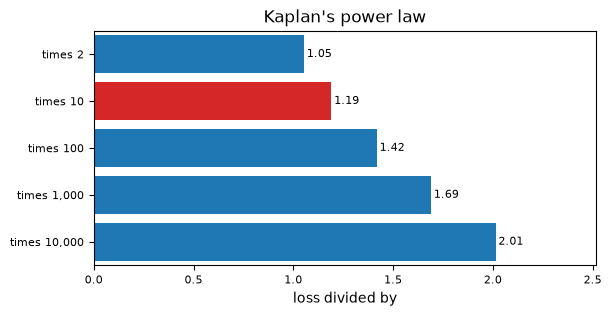

In [2]:
GROWTH = 10
show_factor(GROWTH)

### Solution

In [3]:
display(Markdown(f"A tenfold increase divides the loss by {10 ** ALPHA_N:.3f} and keeps {10 ** -ALPHA_N:.3f} of it, a hundredfold by "
                 f"{100 ** ALPHA_N:.3f}, and 10,000-fold, from {100 * MILLION:,} parameters to {TRILLION:,}, "
                 f"by {10000 ** ALPHA_N:.3f}, which about halves the loss. The factor depends on the "
                 f"growth alone, so each tenfold step buys the same factor and a smaller absolute drop than the step before."))

A tenfold increase divides the loss by 1.191 and keeps 0.839 of it, a hundredfold by 1.419, and 10,000-fold, from 100,000,000 parameters to 1,000,000,000,000, by 2.014, which about halves the loss. The factor depends on the growth alone, so each tenfold step buys the same factor and a smaller absolute drop than the step before.

## 2. A compute budget and its optimum

A training run costs about 6 FLOPs per parameter per token. Hoffmann et al.
found the best loss for a budget at about 20 tokens per parameter, so the
budget fixes the number of parameters. Run the cell with the budget of
Gopher and Chinchilla, `5.76 * 10 ** 23` FLOPs. Then set `BUDGET` to
GPT-3's, `3.14 * 10 ** 23`: what size does the rule give, and by what factor
is GPT-3 larger?

5.76 × 10^23 FLOPs: 69.3 billion parameters on 1,386 billion tokens; Gopher 4.04 times the optimum of its own budget; GPT-3 3.42 times the optimum of its own budget; Chinchilla 1.01 times the optimum of its own budget


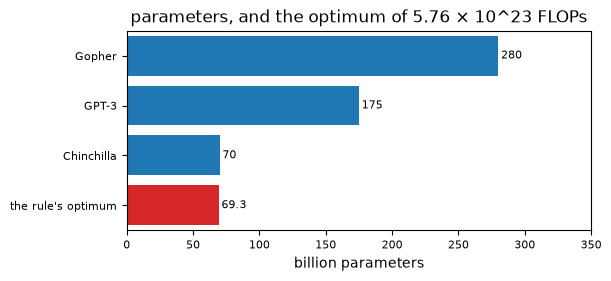

In [4]:
BUDGET = 5.76 * 10 ** 23
show_budget(BUDGET)

### Solution

In [5]:
(g, _, c, mg), (t, _, ct, mt), (h, _, _, mh) = MODELS.values()
display(Markdown(f"At {sci(c)} FLOPs the rule gives {optimum(c)[0] / BILLION:.1f} billion parameters on {optimum(c)[1] / TRILLION:.2f} trillion "
                 f"tokens: Chinchilla's {h / BILLION:.0f} billion sits at the optimum and Gopher is {g / optimum(c)[0]:.2f} times too large. At "
                 f"{sci(ct)} it gives {optimum(ct)[0] / BILLION:.1f} billion, and GPT-3 is {t / optimum(ct)[0]:.2f} times too large. On MMLU's "
                 f"{MMLU_TASKS} tasks Chinchilla scores {mh}, Gopher {mg} and GPT-3 {mt}: the model at its optimum scores highest."))

At 5.76 × 10^23 FLOPs the rule gives 69.3 billion parameters on 1.39 trillion tokens: Chinchilla's 70 billion sits at the optimum and Gopher is 4.04 times too large. At 3.14 × 10^23 it gives 51.2 billion, and GPT-3 is 3.42 times too large. On MMLU's 57 tasks Chinchilla scores 67.6, Gopher 60.0 and GPT-3 43.9: the model at its optimum scores highest.

## 3. Exact match on digits

An answer of `DIGITS` digits counts as right only when every digit is right.
With each digit right with probability p, independently, exact match is p to
the power `DIGITS`. Run the cell for 4 digits. Then set `DIGITS` to 8: what
exact-match score does a per-digit accuracy of 0.9 give?

4 digits: 0.10 per digit gives 0.0001; 0.50 per digit gives 0.0625; 0.90 per digit gives 0.6561; 0.99 per digit gives 0.9606


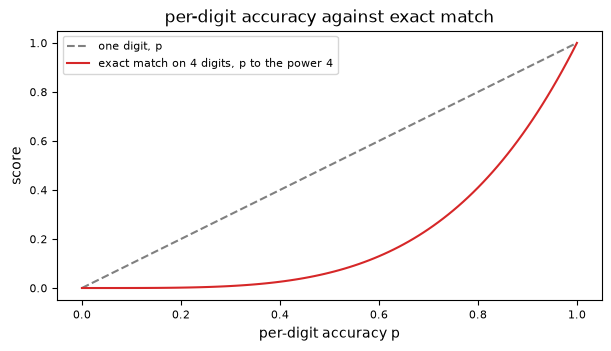

In [6]:
DIGITS = 4
show_exact(DIGITS)

### Solution

In [7]:
display(Markdown(f"At 0.5 per digit, four-digit exact match is {0.5 ** 4:.4f}; at 0.9 per digit, eight digits give {0.9 ** 8:.2f}. The "
                 f"per-digit curve rises evenly, while exact match on {8} digits stays under {0.5 ** 8 * 100:.1f} per cent up to 0.5 "
                 f"per digit and then climbs to {0.99 ** 8:.2f} at 0.99: a smooth gain, scored by exact match, looks like a late jump."))

At 0.5 per digit, four-digit exact match is 0.0625; at 0.9 per digit, eight digits give 0.43. The per-digit curve rises evenly, while exact match on 8 digits stays under 0.4 per cent up to 0.5 per digit and then climbs to 0.92 at 0.99: a smooth gain, scored by exact match, looks like a late jump.

## Appendix. Training memory on eight GPUs

Adam in mixed precision keeps, per parameter, 2 bytes for the fp16 weights,
2 for the gradients and 12 of optimiser state. Data parallelism
copies all of it onto every GPU. ZeRO stage 1 shards the optimiser state over
the GPUs, stage 2 the gradients as well, and stage 3 the weights too. The
cell shows a model of 7 billion parameters on 8 GPUs.

7 billion parameters on 8 GPUs, GB per GPU: data parallel 112.00; ZeRO stage 1 38.50; ZeRO stage 2 26.25; ZeRO stage 3 14.00


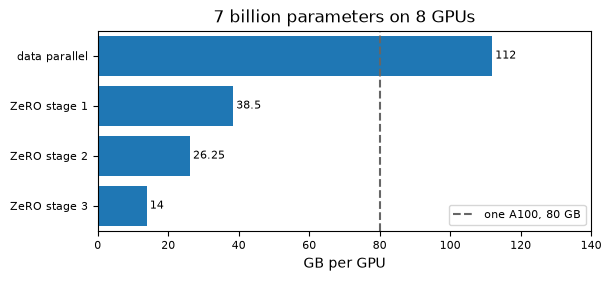

In [8]:
show_memory(7 * BILLION, 8)

**Exercise.** The cell holds Mixtral: 8 experts of 5.67 billion parameters,
1.67 billion shared, 2 experts run per token. Give its total and active
parameters and its memory per GPU on 8 GPUs under ZeRO stage 3. Then set
`TOP` to 1: which of the numbers change?

total 47.0 billion parameters, active 13.0 billion per token
47 billion parameters on 8 GPUs, GB per GPU: data parallel 752.48; ZeRO stage 1 258.67; ZeRO stage 2 176.36; ZeRO stage 3 94.06


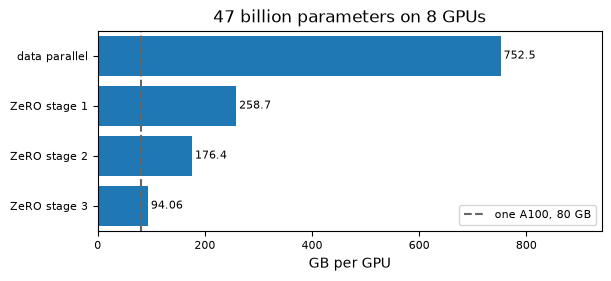

In [9]:
EXPERTS = 8
EXPERT_SIZE = 5.67 * BILLION
SHARED = 1.67 * BILLION
TOP = 2

total, active = experts(EXPERTS, EXPERT_SIZE, SHARED, TOP)
print(f"total {total / BILLION:.1f} billion parameters, active {active / BILLION:.1f} billion per token")
show_memory(total, 8)

### Solution

In [10]:
(total2, active2), (total1, active1) = experts(8, 5.67 * BILLION, 1.67 * BILLION, 2), experts(8, 5.67 * BILLION, 1.67 * BILLION, 1)
display(Markdown(f"Mixtral stores {total2 / BILLION:.1f} billion parameters and runs {active2 / BILLION:.1f} billion per token. Its training "
                 f"state takes {per_gpu(total2, 8)['ZeRO stage 3']:.1f} GB per GPU on 8 GPUs under ZeRO stage 3, over one {GPU_GB} GB "
                 f"A100. With `TOP` at 1 the active parameters fall to {active1 / BILLION:.1f} billion; the total, "
                 f"{total1 / BILLION:.1f} billion, and the memory stay as they are."))

Mixtral stores 47.0 billion parameters and runs 13.0 billion per token. Its training state takes 94.1 GB per GPU on 8 GPUs under ZeRO stage 3, over one 80 GB A100. With `TOP` at 1 the active parameters fall to 7.3 billion; the total, 47.0 billion, and the memory stay as they are.